# Event detection on League of Legends broadcast video
### Experiment report: from a first U-Net to a BiGRU, and what each experiment taught us

This notebook documents the experiments run on the **LoL-V2T** dataset to detect game events (`kill`, `objective`, `teamfight`) in broadcast video, from the first baseline to the final model. Every table and figure is computed from the committed checkpoints (`checkpoints/`) and the saved training histories (`visualisation/results/`), so the report can be re-run end to end.

**Contents**

1. Task and data
2. Evaluation protocol and metrics
3. Models and their receptive fields
4. The experiments (in the order they were run)
   1. First baselines: variational and plain U-Net
   2. Gradient-free weight editing
   3. Regularisation (and a monitoring pitfall)
   4. Class weights
   5. Label alignment (a hint from the dataset paper)
   6. Resampling: background downsampling and event-centred crops
   7. Wider temporal context
   8. BiGRU regularisation with background downsampling
   9. Scaling up: a 116M-parameter transformer
5. Overall comparison
6. The best model in detail
7. Conclusions, limitations and next steps

Appendix A: evaluate any checkpoint yourself, step by step. Appendix B: how to reproduce.

In [1]:
import json
import os
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "visualisation" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from common.device import torch_device  # noqa: E402
from common.lolv2t import CLASSES  # noqa: E402
from detection.gpu_data import EvalSet, GpuSplit  # noqa: E402
from detection.model import build_model  # noqa: E402
from detection.plot_confusion import draw  # noqa: E402
from detection.score_fast import show_matrix  # noqa: E402
from detection.weight_search import evaluate, rank_metrics  # noqa: E402

# detection.plot_confusion selects a file-only backend; show figures inline in the notebook
%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.width", 200)

RES = ROOT / "visualisation" / "results"
OUT = ROOT / "visualisation" / "output"
OUT.mkdir(exist_ok=True)
device = torch_device("auto")
base_cfg = yaml.safe_load((ROOT / "detection" / "configs" / "default.yaml").read_text())
DATA_ROOT, TOL = Path(base_cfg["root"]), base_cfg["tolerance_s"]
HAVE_DATA = all((DATA_ROOT / "cache" / f"{s}_rgbflow.f16").exists() for s in ("val", "test"))

manifest = pd.DataFrame(json.loads((ROOT / "checkpoints" / "manifest.json").read_text())).set_index("name")

# scores of every checkpoint on train/val/test (computed once by detection.score_all, then cached)
if not (RES / "scores.json").exists():
    subprocess.run([sys.executable, "-m", "detection.score_all", "--out", str(RES / "scores.json")], check=True)
S = json.loads((RES / "scores.json").read_text())
H = json.loads((RES / "histories.json").read_text())      # per-epoch training monitors
EARLY = json.loads((RES / "early_curves.json").read_text())  # logs of the first two runs
WE = json.loads((RES / "weight_edit.json").read_text())   # weight-editing experiment

print(f"{len(manifest)} checkpoints | device {device} | data on disk for live cells: {HAVE_DATA}")

35 checkpoints | device cuda | data on disk for live cells: True


In [2]:
def metrics_row(r):
    st = r["step"]
    return {"loss": r["ce"], "acc": st["accuracy"], "AUROC": r["rank"]["mean_auroc"],
            "AP lift": r["rank"]["mean_ap"] / r["rank"]["mean_base_rate"], "step R": st["macro_recall"],
            "step F1": st["macro_f1"], "event P": r["mean_event_precision"],
            "event R": r["mean_event_recall"], "event F1": r["mean_event_f1"]}


def table(names, splits=("test",)):
    # one row per model (single split) or per model and split
    rows = [{"model": n, "split": sp, **metrics_row(S[n][sp])} for n in names for sp in splits]
    df = pd.DataFrame(rows)
    return df.set_index(["model", "split"]) if len(splits) > 1 else df.drop(columns="split").set_index("model")


def show(df, hi=("AUROC", "step R", "step F1", "event F1", "acc")):
    fmt = {c: "{:.3f}" for c in df.columns if df[c].dtype.kind == "f"}
    return df.style.format(fmt).highlight_max(subset=[c for c in hi if c in df.columns], color="#cfe8cf")


def cm_grid(names, split="test", ncols=3, titles=None):
    n = len(names)
    rows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(rows, ncols, figsize=(5.3 * ncols, 4.9 * rows), layout="constrained", squeeze=False)
    axes = axes.ravel()
    for ax, name in zip(axes, names, strict=False):
        im = draw(ax, S[name][split]["step"], (titles or {}).get(name, f"{name} | {split}"))
        ax.grid(False)
    for ax in axes[n:]:
        ax.axis("off")
    fig.colorbar(im, ax=axes.tolist(), shrink=0.7, label="share of true class")
    plt.show()


def curves(runs, left, right=None, titles=None, figsize=(13, 4)):
    # plot per-epoch training/validation monitors from the saved histories
    fig, axes = plt.subplots(1, len(left), figsize=figsize, squeeze=False)
    for ax, (key_train, key_val, label) in zip(axes[0], left, strict=True):
        for r in runs:
            h = pd.DataFrame(H[r]["history"])
            (line,) = ax.plot(h["epoch"], h[key_val], label=r)
            ax.plot(h["epoch"], h[key_train], "--", color=line.get_color(), alpha=0.7)
        ax.set_xlabel("epoch")
        ax.set_ylabel(label)
        ax.set_title(label + ": train (dashed) vs validation (solid)", fontsize=10)
        ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5), title="run (colour)")
    fig.tight_layout()
    plt.show()

## Summary of results

In [3]:
best = "gru_reg2"
t, v, tr = S[best]["test"], S[best]["val"], S[best]["train"]
first = S["detector_unet"]["test"]
display(Markdown(f'''
* **Best model:** `{best}`, a 2-layer bidirectional GRU ({int(manifest.loc[best, "parameters"]):,} parameters) trained with background downsampling on labels shifted +6 s.
  Test AUROC **{t["rank"]["mean_auroc"]:.3f}** (validation {v["rank"]["mean_auroc"]:.3f}), up from {first["rank"]["mean_auroc"]:.3f} for the first U-Net.
* **Target not yet reached:** the goal was a test AUROC between 0.7 and 0.8. The best model is {0.7 - t["rank"]["mean_auroc"]:.3f} below 0.7 on test (it reaches {v["rank"]["mean_auroc"]:.3f} on validation).
* **Confusion matrix:** with background downsampling, test recall is background {t["step"]["per_class"]["background"]["recall"]:.2f}, kill {t["step"]["per_class"]["kill"]["recall"]:.2f},
  objective {t["step"]["per_class"]["objective"]["recall"]:.2f}, teamfight {t["step"]["per_class"]["teamfight"]["recall"]:.2f}. Events are found, but precision is low (about 0.07 to 0.08 per event class).
* **Transformers:** a 116.6M-parameter transformer encoder (the largest that fits on this GPU) reaches test AUROC 0.677 to 0.680, below the 0.39M-parameter BiGRU. Performance rises with size (0.618 at 0.33M, 0.670 at 5.8M) and then saturates, and the big model overfits after about 5 epochs.
* **What moved the needle:** regularising the U-Net (test AUROC 0.56 to 0.61), the label window (shifting it later, +0.04), temporal context (a wider receptive field, +0.03), and early stopping on a train-vs-validation monitor.
  **What did not:** class weights, background downsampling and crops (they move the operating point), extra capacity (a 6.4M U-Net, a 116.6M transformer), and heavier regularisation of the BiGRU.
'''))


* **Best model:** `gru_reg2`, a 2-layer bidirectional GRU (387,140 parameters) trained with background downsampling on labels shifted +6 s.
  Test AUROC **0.693** (validation 0.711), up from 0.563 for the first U-Net.
* **Target not yet reached:** the goal was a test AUROC between 0.7 and 0.8. The best model is 0.007 below 0.7 on test (it reaches 0.711 on validation).
* **Confusion matrix:** with background downsampling, test recall is background 0.64, kill 0.24,
  objective 0.43, teamfight 0.16. Events are found, but precision is low (about 0.07 to 0.08 per event class).
* **Transformers:** a 116.6M-parameter transformer encoder (the largest that fits on this GPU) reaches test AUROC 0.677 to 0.680, below the 0.39M-parameter BiGRU. Performance rises with size (0.618 at 0.33M, 0.670 at 5.8M) and then saturates, and the big model overfits after about 5 epochs.
* **What moved the needle:** regularising the U-Net (test AUROC 0.56 to 0.61), the label window (shifting it later, +0.04), temporal context (a wider receptive field, +0.03), and early stopping on a train-vs-validation monitor.
  **What did not:** class weights, background downsampling and crops (they move the operating point), extra capacity (a 6.4M U-Net, a 116.6M transformer), and heavier regularisation of the BiGRU.


## 1. Task and data

**Dataset.** LoL-V2T (Tanaka and Simo-Serra, CVPR Workshops 2021): 9,723 League of Legends Worlds clips with 62,677 timestamped commentary sentences, split into **6,977 train, 851 validation and 1,895 test clips**. Each clip comes with precomputed features: a TSN ResNet-50 RGB feature and a TSN optical-flow feature per sampled frame, concatenated into **4,096 numbers per step**, one step about **0.217 s** apart. The raw video is not distributed.

**What the dataset paper does.** It targets *video captioning* (generating the commentary text) with a vanilla transformer and with MART (a transformer with a recurrent memory), and reports BLEU@4 / ROUGE-L / METEOR. There are **no event labels** and no classification task. The paper also points out that the timestamp of a caption often does not match the moment of the action.

**Our task.** Detect events per time step. Because there are no event labels we derive **weak labels from the commentary**: a sentence that matches keyword rules for `kill`, `objective` or `teamfight` labels the steps in a 3-second window that starts `label_offset_s` seconds after the sentence starts; every other step is `background`. The model reads a clip's `(T, 4096)` feature sequence and outputs one of four classes for each step. Event times (used for the event-level metrics) are the start of each labelled window.

Two properties of these labels shape everything that follows: the data are heavily imbalanced, and the labels are noisy (commentary lags or leads the action, and keywords misfire).

In [4]:
rows = []
for off in (0.0, 6.0):
    for split in ("train", "val", "test"):
        gs = GpuSplit(DATA_ROOT, split, {**base_cfg, "label_offset_s": off}, device) if HAVE_DATA else None
        if gs is None:
            continue
        y = torch.cat(gs.y)
        counts = torch.bincount(y, minlength=4).cpu().numpy()
        has_ev = sum(int((t > 0).any()) for t in gs.y)
        rows.append({"label offset (s)": off, "split": split, "clips": len(gs), "steps": int(counts.sum()),
                     "clips with events": f"{has_ev} ({has_ev / len(gs):.0%})",
                     **{f"% {c}": 100 * counts[i] / counts.sum() for i, c in enumerate(CLASSES)}})
stats = pd.DataFrame(rows)
display(stats.style.format({f"% {c}": "{:.1f}" for c in CLASSES}).hide(axis="index"))

label offset (s),split,clips,steps,clips with events,% background,% kill,% objective,% teamfight
0.000000,train,6977,795299,3608 (52%),87.7,3.8,5.1,3.5
0.000000,val,851,95734,437 (51%),88.1,3.6,5.4,2.9
0.000000,test,1895,235815,1010 (53%),88.1,3.9,4.7,3.3
6.000000,train,6977,795299,3180 (46%),89.4,3.2,4.4,3.0
6.000000,val,851,95734,379 (45%),89.9,3.3,4.3,2.5
6.000000,test,1895,235815,898 (47%),89.8,3.3,4.0,2.9


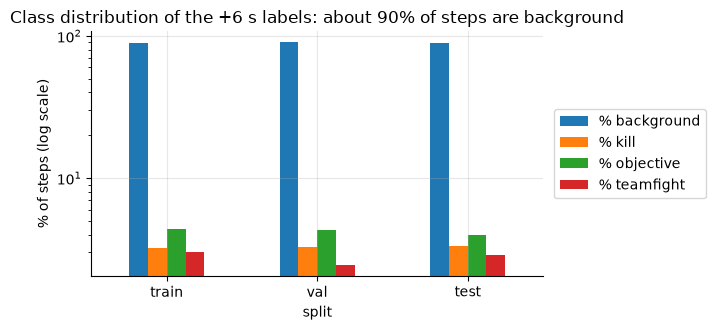

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.4))
sub = stats[stats["label offset (s)"] == 6.0].set_index("split")
sub[[f"% {c}" for c in CLASSES]].plot.bar(ax=ax, rot=0, logy=True)
ax.set_ylabel("% of steps (log scale)")
ax.set_title("Class distribution of the +6 s labels: about 90% of steps are background")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()

## 2. Evaluation protocol and metrics

**Splits and selection.** The model, epoch, and confidence threshold are chosen on the **validation** set. The **test** set is used for reporting only. The training set is also scored (in evaluation mode, without dropout or noise) to measure overfitting.

**Metrics.**

* **Loss**: cross-entropy over all steps, unweighted.
* **Accuracy**: share of steps with the right class. It is misleading here: a model that always says "background" gets about 0.9.
* **Step-level precision, recall and F1**: computed per class and macro-averaged over the four classes. Recall of a class is its row-normalised share in the confusion matrix.
* **Event-level precision, recall and F1**: a run of at least 2 steps of the same class, whose top probability exceeds `min_conf`, becomes one event; it is correct if it lies within ±3 s of a labelled event of that class (greedy one-to-one matching). Pooled over clips, averaged over the three event classes.
* **AUROC and AP (average precision)**, one class against the rest, from the step probabilities. These do **not** depend on a threshold, class weights or resampling, so they measure how well the classes are separated. Chance AUROC is 0.5; AP is compared with the class base rate (shown as "AP lift").
* **Confusion matrix**: step-level, arg-max class, rows are the true class.

**Threshold.** `min_conf` is picked per model on validation from `{0.2, ..., 0.7}` by mean event F1. **Label offsets.** Models trained with a different label offset are scored against their own labels, so numbers are only comparable within an offset.

**Overfitting monitor.** From the GPU trainer on, every epoch scores a fixed set of 500 training clips and the whole validation set with the same metrics, and training stops when the train-minus-validation gap in CE, event F1 or AUROC stays above 0.10 for three epochs. The saved checkpoint is the best epoch on validation.

## 3. Models and their receptive fields

All models are light enough for an 11 GB GPU. They take a `(batch, 4096, T)` feature sequence and return per-step logits.

* **Variational U-Net**: 1D U-Net over time with a variational bottleneck and a reconstruction head (the original design of the repository).
* **U-Net**: the same without the variational parts; plain cross-entropy. Variants: number of levels, hidden width, blocks per level, input dropout and input noise.
* **Dilated convolutions**: residual dilated convolutions.
* **BiGRU**: a 1x1 projection of the 4,096 features followed by a bidirectional GRU, so every step sees the whole clip.
* **Transformer encoder**: a 1x1 projection, sinusoidal positions and pre-norm self-attention blocks over the whole clip (section 4.9). Sizes from 0.33M to 116.6M parameters.

The **receptive field** (how many steps around a step can influence its prediction) is measured below from gradients on a randomly initialised copy of each model.

In [6]:
def receptive_field(arch, kwargs, length=500):
    torch.manual_seed(0)
    net = build_model(arch, 4096, **kwargs).eval()
    x = torch.randn(1, 4096, length, requires_grad=True)
    out = net(x)
    out = out["logits"] if isinstance(out, dict) else out
    out[0, :, length // 2].sum().backward()
    nz = (x.grad[0].abs().sum(0) > 0).nonzero().flatten()
    return int(nz.max() - nz.min() + 1)


RF = {n: receptive_field(r["arch"], r["model_kwargs"]) for n, r in manifest.iterrows()}
manifest["receptive field (steps)"] = pd.Series(RF)
manifest["receptive field (s)"] = manifest["receptive field (steps)"] * 0.217
# the BiGRU sees the whole clip: the measured value only reflects the 500-step test input
whole = manifest["arch"].isin(["bigru", "transformer"])
manifest["receptive field"] = [("whole clip" if w else f"{s:.0f} s ({k} steps)") for w, s, k in
                               zip(whole, manifest["receptive field (s)"], manifest["receptive field (steps)"], strict=True)]
families = manifest.drop_duplicates(["arch", "parameters"])[["arch", "parameters", "receptive field", "description"]]
families.style.format({"parameters": "{:,}"}).hide(axis="index")

[W1112 13:35:21.683392229 NNPACK.cpp:62] Could not initialize NNPACK! Reason: Unsupported hardware.


arch,parameters,receptive field,description
vunet,"1,645,764",10 s (47 steps),"Variational U-Net (CE + reconstruction + KL), first trainer, early stopped"
unet,"1,149,252",10 s (47 steps),"Plain U-Net, first trainer, epoch 30 of 100"
unet,"353,444",10 s (47 steps),"U-Net hidden 32, stronger regularisation"
unet,"121,428",10 s (47 steps),"U-Net hidden 16, input dropout 0.5, wd 0.05"
unet,"294,100",23 s (107 steps),U-Net 3 levels (receptive field 99 steps)
unet,"983,508",48 s (219 steps),U-Net 4 levels (219 steps)
unet,"6,418,212",88 s (407 steps),"U-Net 4 levels, hidden 32, 2 blocks per level (6.4M params)"
dilated,"336,580",28 s (127 steps),Dilated residual convolutions 1..32 (127 steps)
bigru,"387,140",whole clip,"BiGRU, 2 layers, hidden 64 (whole clip), class weights 0.75"
bigru,"162,852",whole clip,"BiGRU hidden 32, more regularisation, background downsampling"


## 4. The experiments

Each experiment answers one question; the next one follows from what the previous one showed.

### 4.1 First baselines: variational and plain U-Net

**Question.** How well does the repository's original model (a variational U-Net with a reconstruction head) do, and does the variational part help?

**Setup.** Both were trained with the first trainer (`detection/train.py`): class-weighted cross-entropy (square-root inverse frequency), AdamW, up to 100 epochs, checkpoint chosen by validation event F1 at a fixed `min_conf` of 0.5. Training ran for 74 (variational) and 76 (plain) epochs before I stopped it, because validation had stopped improving long before. The variational model adds a reconstruction MSE and a KL term to the loss.

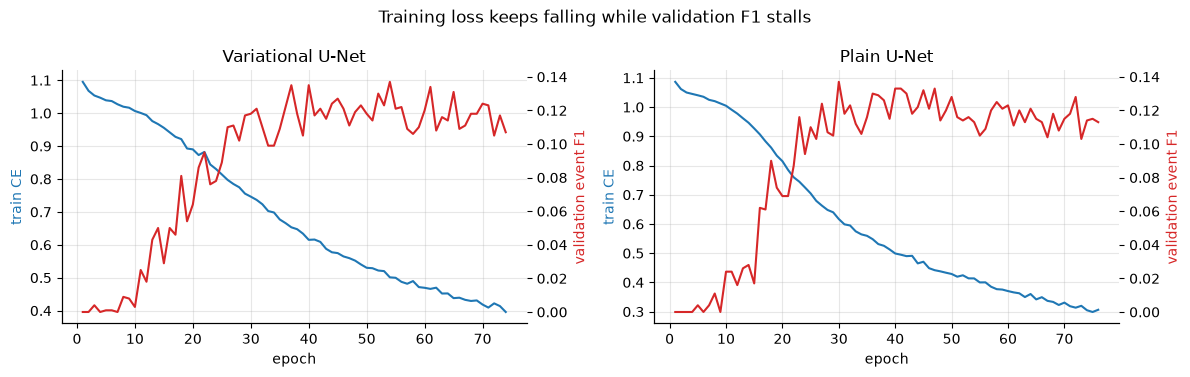

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, name in zip(axes, ("vunet", "unet"), strict=True):
    e = pd.DataFrame(EARLY[name])
    ax.plot(e["epoch"], e["train_ce"], label="train cross-entropy (weighted, dropout on)", color="tab:blue")
    ax.set_xlabel("epoch")
    ax.set_ylabel("train CE", color="tab:blue")
    ax2 = ax.twinx()
    ax2.plot(e["epoch"], e["val_event_f1"], color="tab:red", label="validation event F1 (min_conf 0.5)")
    ax2.set_ylabel("validation event F1", color="tab:red")
    ax2.grid(False)
    ax.set_title({"vunet": "Variational U-Net", "unet": "Plain U-Net"}[name])
fig.suptitle("Training loss keeps falling while validation F1 stalls")
fig.tight_layout()
plt.show()

In [8]:
show(table(["detector", "detector_unet"], ("train", "val", "test")))

**What we learned.**

* The training loss falls steadily (from about 1.1 to 0.3 to 0.4) but validation event F1 peaks around 0.14 (epoch 30 for the plain U-Net, epoch 54 for the variational one) and then stays flat or drifts down: the models memorise the training clips. On the training set the plain U-Net reaches an event F1 of about 0.45, on test about 0.13.
* The **reconstruction loss of the variational model stays near 1.0** (the input is standardised, so an MSE of 1.0 means almost nothing is reconstructed). The latent carries little useful information and the variational parts do not help; the variational and plain U-Net are tied on test.
* Test AUROC is only about 0.56: the classes are barely separable by these models. This is the starting point.

### 4.2 Gradient-free weight editing ("weight-space programming")

**Question.** Can a trained checkpoint be improved by editing its weights directly, with no gradient, scored only on training clips?

**Setup.** A copy of the plain U-Net checkpoint was changed by (A) a line search on the four output biases, (B) random mutations of the output layer's weights, and (C) block-wise random mutations of all weights with an adaptive step size. A mutation was kept only if it raised event F1 on 1,000 fixed training clips. A second set of 500 other training clips was scored but never used to accept a change. Validation and test were scored once, at the end (at `min_conf` 0.5).

In [9]:
rows = []
for split, label in (("fit", "1,000 fit clips (used to accept edits)"), ("holdout", "500 other training clips"), ("val", "validation"), ("test", "test")):
    rows.append({"scored on": label, "original": WE["original"][split]["mean_event_f1"], "edited": WE["edited"][split]["mean_event_f1"]})
we = pd.DataFrame(rows).set_index("scored on")
we["change"] = we["edited"] - we["original"]
display(we.style.format("{:+.3f}", subset=["change"]).format("{:.3f}", subset=["original", "edited"]))
print(f"{WE['n_evals']:,} candidate edits in {WE['minutes']:.0f} minutes, no gradients")

,original,edited,change
scored on,,,
"1,000 fit clips (used to accept edits)",0.447,0.500,+0.053
500 other training clips,0.453,0.498,+0.045
validation,0.137,0.113,-0.024
test,0.117,0.111,-0.007


4,349 candidate edits in 64 minutes, no gradients


**What we learned.** The search raised the score on the clips it was allowed to look at (event F1 0.447 to 0.500), most of it from the very first step (the four output biases). The gain **did not carry over**: validation and test event F1 went down. The edits mostly changed the balance between classes, not the model's ability to tell them apart. The 500 other *training* clips are not a real hold-out (the original model had been trained on them), so only validation and test count.

### 4.3 Regularisation (and a monitoring pitfall)

**Question.** The U-Net overfits. Can dropout, input noise, weight decay and a smaller first layer fix that?

**Setup.** The U-Net was retrained with the GPU trainer (features cached on the GPU, an epoch takes seconds) and increasing regularisation: `base` (none), `reg2` (dropout 0.2, input dropout 0.3, noise 0.3, weight decay 0.01), `reg3` (hidden width 32, stronger), `reg4` (hidden width 16, input dropout 0.5, weight decay 0.05), `reg5` (input dropout 0.7).

**A pitfall that cost some time.** My first regularised runs looked *worse* than the baseline (validation event F1 0.06 to 0.08 against 0.14). The cause was the fixed confidence threshold of 0.5: regularised models give flatter probabilities, so few steps reached 0.5 and events were suppressed. Choosing `min_conf` on validation removed the gap. The table shows validation event F1 of the final checkpoints as a function of `min_conf`.

In [10]:
names = ["detector_unet", "base_c", "reg2_c", "reg3_c", "reg4_c", "reg5_c"]
conf = pd.DataFrame({n: S[n]["val_f1_by_conf"] for n in names}).T
conf.columns = [f"min_conf {float(c):.1f}" for c in conf.columns]
display(conf.style.format("{:.3f}").background_gradient(axis=1, cmap="Greens"))

,min_conf 0.2,min_conf 0.3,min_conf 0.4,min_conf 0.5,min_conf 0.6,min_conf 0.7
detector_unet,0.139,0.139,0.139,0.136,0.105,0.080
base_c,0.126,0.122,0.105,0.073,0.029,0.010
reg2_c,0.136,0.134,0.125,0.079,0.034,0.010
reg3_c,0.139,0.137,0.105,0.054,0.021,0.008
reg4_c,0.143,0.139,0.113,0.069,0.030,0.009
reg5_c,0.113,0.110,0.089,0.039,0.013,0.002


In [11]:
show(table(["base_c", "reg2_c", "reg3_c", "reg4_c", "reg5_c"], ("train", "val", "test")))

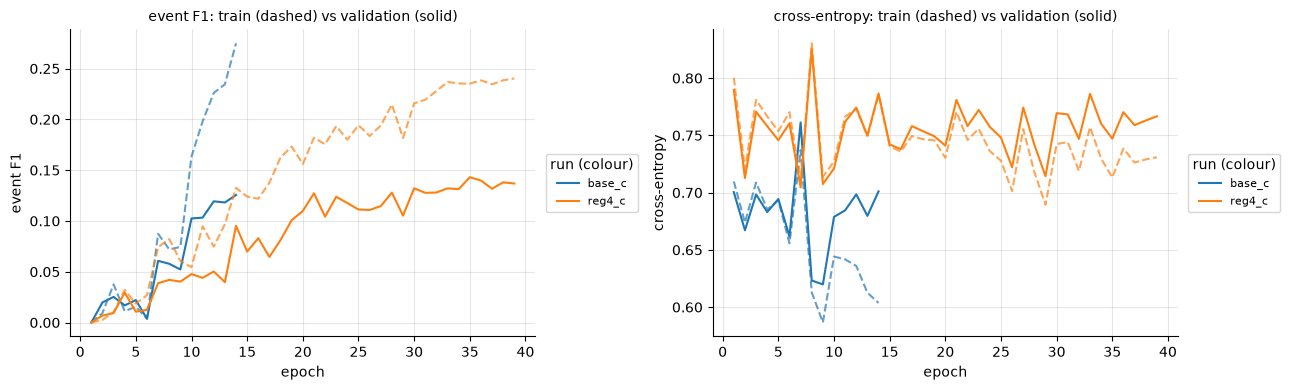

In [12]:
curves(["base_c", "reg4_c"], [("train_f1", "val_f1", "event F1"), ("train_ce", "val_ce", "cross-entropy")])

**What we learned.**

* Regularisation shrinks the train-test gap in event F1 (training F1 from 0.45 for the first U-Net and 0.28 for `base` down to about 0.24, with test event F1 unchanged at 0.13 to 0.14) and **raises test AUROC from 0.56 (first U-Net) and 0.59 (`base`) to 0.60 to 0.61**, the largest single gain of the project.
* More is not better: the strongest input dropout (`reg5`) predicts fewer events and scores lower on event F1.
* The learning curves show the model still separates train from validation after a few epochs; regularisation delays this but does not remove it.
* Lesson: monitor train and validation with the same metric, and tune the decision threshold on validation before comparing models.

### 4.4 Class weights

**Question.** About 90% of steps are background and almost everything is predicted as background. Does weighting the loss by `(inverse class frequency) ** power` help?

**Setup.** Power 0.5 had been the default. We trained power 0.75, 1.0 (full inverse frequency) and 1.25 on the `reg4` network, and power 1.0 on the wider `reg3` network, selecting epochs by step-level macro F1.

In [13]:
show(table(["reg4_c", "wt075", "wt100", "wt125", "wt100_h32"], ("test",)))

,loss,acc,AUROC,AP lift,step R,step F1,event P,event R,event F1
model,,,,,,,,,
reg4_c,0.758,0.820,0.613,1.576,0.279,0.281,0.137,0.133,0.129
wt075,1.004,0.695,0.609,1.580,0.312,0.284,0.111,0.278,0.158
wt100,1.457,0.275,0.589,1.540,0.335,0.176,0.111,0.262,0.155
wt125,1.985,0.051,0.591,1.514,0.318,0.069,0.106,0.308,0.155
wt100_h32,1.732,0.068,0.603,1.529,0.305,0.079,0.084,0.424,0.135


In [14]:
show(table(["reg4_c", "wt075", "wt100", "wt125", "wt100_h32"], ("val",)))

,loss,acc,AUROC,AP lift,step R,step F1,event P,event R,event F1
model,,,,,,,,,
reg4_c,0.747,0.822,0.604,1.485,0.277,0.280,0.147,0.145,0.143
wt075,0.994,0.708,0.603,1.495,0.316,0.289,0.113,0.274,0.160
wt100,1.443,0.301,0.574,1.391,0.325,0.183,0.117,0.263,0.160
wt125,1.972,0.049,0.578,1.364,0.306,0.067,0.111,0.303,0.159
wt100_h32,1.715,0.069,0.605,1.485,0.309,0.080,0.082,0.392,0.129


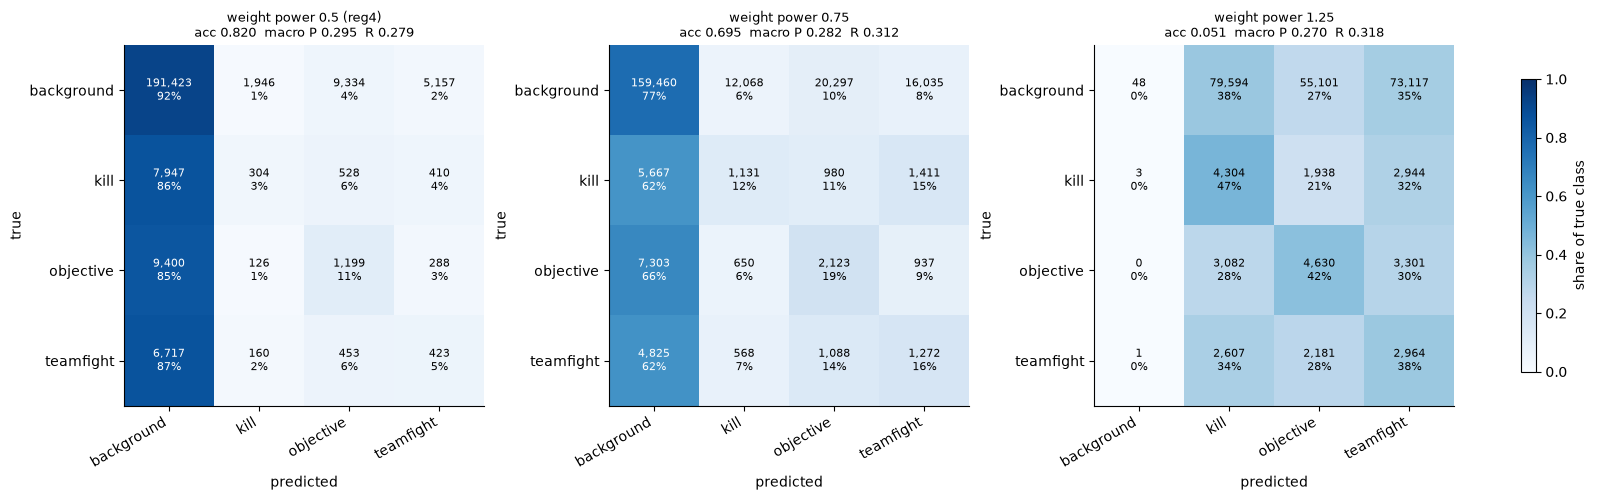

In [15]:
cm_grid(["reg4_c", "wt075", "wt125"], "test", titles={"reg4_c": "weight power 0.5 (reg4)", "wt075": "weight power 0.75", "wt125": "weight power 1.25"})

**What we learned.**

* Heavier weights move predictions away from background: event recall rises, but background recall falls sharply (accuracy 0.82 to 0.70 at power 0.75, and to 0.05 at power 1.25 where almost every step is called an event).
* The best event F1 (about 0.158) comes at power 0.75, a modest gain.
* **AUROC stays at about 0.59 to 0.61 for all of them.** Weighting changes where the decision threshold sits, not how well the classes are separated. This is expected: AUROC does not depend on class priors.
* So rebalancing alone cannot reach the AUROC target. It is a way to choose an operating point.

### 4.5 Label alignment (a hint from the dataset paper)

**Question.** The paper says that the content of a caption often happens *before* the caption's timestamp, because narrators describe what they just saw. Our labels used the window starting at the caption start. Does a different window help?

**Setup.** A new `label_offset_s` shifts the labelled window to `[t + offset, t + offset + 3 s)` (and the event times used for the event metrics along with it). Seven models were trained on the same setup (the `wt075` configuration) with offsets from -9 s to +9 s. Because the labels change with the offset, event F1 is not comparable across offsets; **AUROC and AP lift are** (the window length, and so the base rate, is nearly constant).

,val AUROC,test AUROC,test AP lift,test step R,test step F1,test acc
label offset (s),,,,,,
-9,0.611,0.604,1.476,0.299,0.276,0.769
-6,0.612,0.615,1.604,0.313,0.283,0.749
-3,0.604,0.611,1.532,0.296,0.280,0.762
0,0.620,0.617,1.558,0.305,0.289,0.738
3,0.642,0.633,1.550,0.305,0.282,0.723
6,0.669,0.654,1.616,0.303,0.283,0.752
9,0.665,0.657,1.688,0.313,0.276,0.713


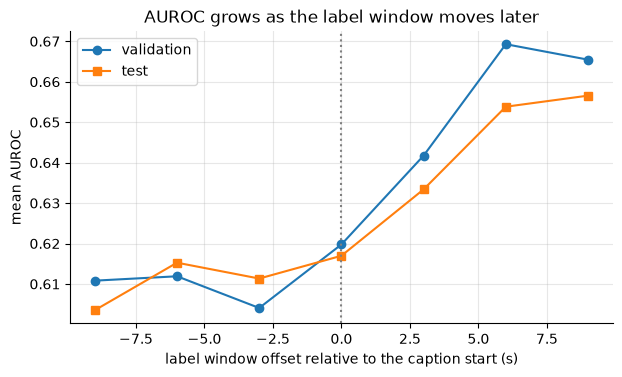

In [16]:
offs = [("shift_m9", -9), ("shift_m6", -6), ("shift_m3", -3), ("shift0", 0), ("shift_p3", 3), ("shift_p6", 6), ("shift_p9", 9)]
rows = []
for n, off in offs:
    rows.append({"label offset (s)": off, "val AUROC": S[n]["val"]["rank"]["mean_auroc"], "test AUROC": S[n]["test"]["rank"]["mean_auroc"],
                 "test AP lift": S[n]["test"]["rank"]["mean_ap"] / S[n]["test"]["rank"]["mean_base_rate"],
                 "test step R": S[n]["test"]["step"]["macro_recall"], "test step F1": S[n]["test"]["step"]["macro_f1"],
                 "test acc": S[n]["test"]["step"]["accuracy"]})
offtab = pd.DataFrame(rows).set_index("label offset (s)")
display(offtab.style.format("{:.3f}").highlight_max(subset=["val AUROC", "test AUROC", "test AP lift"], color="#cfe8cf"))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(offtab.index, offtab["val AUROC"], "o-", label="validation")
ax.plot(offtab.index, offtab["test AUROC"], "s-", label="test")
ax.axvline(0, color="grey", ls=":")
ax.set_xlabel("label window offset relative to the caption start (s)")
ax.set_ylabel("mean AUROC")
ax.set_title("AUROC grows as the label window moves later")
ax.legend()
plt.show()

**What we learned.** The paper's hint, taken as "look earlier", **did not hold for our keyword labels**: windows before the caption (-9 to -3 s) are no better than the original (AUROC 0.60 to 0.62 on test). AUROC rises as the window moves *later* and levels off at +6 to +9 s (about 0.65 to 0.66 on test, AP lift about 1.6 to 1.7). I do not know the cause; the dataset's caption timestamps are interpolated from word counts of the speech chunks, which could place them systematically early. The +6 s window was used for all later experiments.

Step-level macro F1 and recall barely change with the offset (about 0.28 and 0.30): the shift improves the *ranking* of steps, not the decisions at one threshold.

### 4.6 Resampling: background downsampling and event-centred crops

**Question.** Instead of weighting the loss, can we rebalance by *resampling*: random crops centred on events, and dropping most background steps?

**Setup.** On the +6 s labels, with the `reg4` network: a **control** (class weights 0.75) against **event-centred crops** (40 to 100 steps, 70% of them containing an event) combined with **per-batch background downsampling** to the mean event-class count, with no class weights. Checkpoints were selected on validation AUROC. (I started a wider sweep, with background downsampling alone, clip oversampling and crops alone, and stopped it to run the combination you asked for, so only these two runs exist.)

In [17]:
show(table(["rs0_control", "rs5_balance_crops"], ("train", "val", "test")))

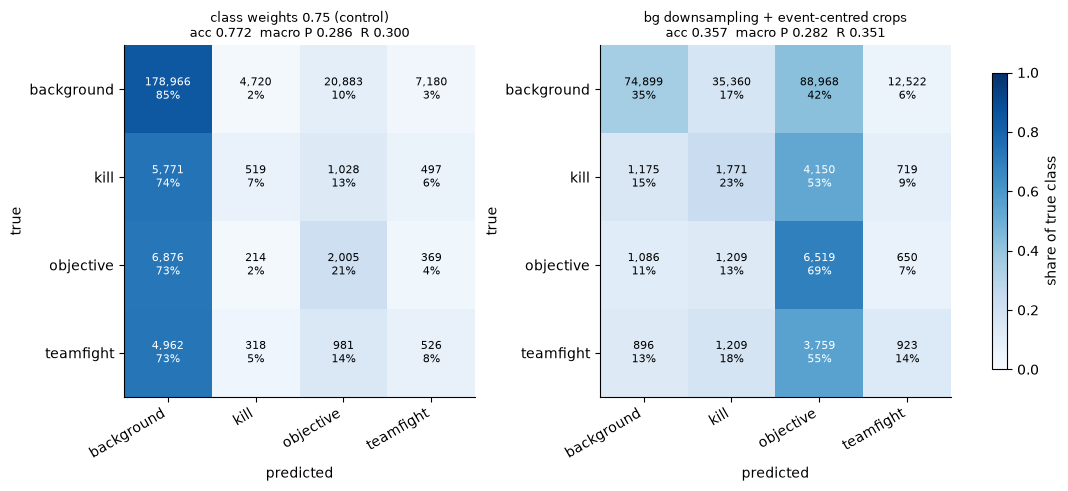

In [18]:
cm_grid(["rs0_control", "rs5_balance_crops"], "test", ncols=2, titles={"rs0_control": "class weights 0.75 (control)", "rs5_balance_crops": "bg downsampling + event-centred crops"})

**What we learned.** Downsampling plus crops produces the kind of confusion matrix that was asked for, with fewer events lost to background (event recall rises, background recall falls to about 0.35), but **AUROC is lower** (test 0.634 against 0.657) and precision drops. This is the same operating-point effect as the class weights, and the crops did not give the model a better view of the events. Background downsampling is kept as the standing default from here on, because it gives the confusion matrix the project wants, with the understanding that it is not expected to raise AUROC.

### 4.7 Wider temporal context

**Question.** The +6 s labels depend on frames well away from a step. Does a wider receptive field help?

**Setup.** Same regularisation and +6 s labels as the control (receptive field about 10 s). Models: U-Net with 3 and 4 levels, a U-Net with 4 levels and twice the width and blocks (6.4M parameters), residual dilated convolutions (1 to 32), and a 2-layer BiGRU that sees the whole clip. (An earlier statement of mine that the control saw only "a few seconds" was wrong; measured through gradients it sees about 10 s.)

,params,receptive field,loss,acc,AUROC,AP lift,step R,step F1,event P,event R,event F1
model,,,,,,,,,,,
rs0_control,"121,428",10 s (47 steps),1.008829,0.771859,0.656550,1.639540,0.300237,0.284547,0.108839,0.181364,0.133308
ctx_unet_l3,"294,100",23 s (107 steps),0.974386,0.732761,0.677797,1.768020,0.317845,0.287047,0.101949,0.252856,0.145253
ctx_unet_l4,"983,508",48 s (219 steps),1.028534,0.636931,0.678108,1.721641,0.333996,0.272188,0.103318,0.248381,0.145462
ctx_unet_l4_big,"6,418,212",88 s (407 steps),1.023263,0.754269,0.675825,1.755148,0.313348,0.290439,0.101918,0.249918,0.141165
ctx_dilated,"336,580",28 s (127 steps),0.969835,0.728219,0.675367,1.834220,0.324376,0.289259,0.089743,0.269423,0.128066
ctx_bigru,"387,140",whole clip,0.945612,0.742904,0.691405,1.951863,0.334060,0.301155,0.131653,0.142105,0.136042


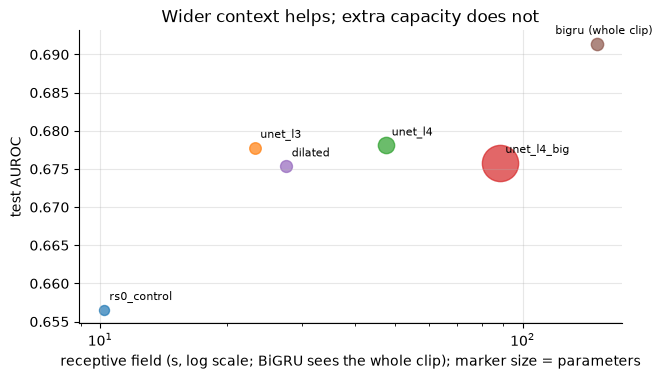

In [19]:
ctx = ["rs0_control", "ctx_unet_l3", "ctx_unet_l4", "ctx_unet_l4_big", "ctx_dilated", "ctx_bigru"]
t = table(ctx, ("test",))
t.insert(0, "receptive field", [manifest.loc[n, "receptive field"] for n in ctx])
t.insert(0, "params", [int(manifest.loc[n, "parameters"]) for n in ctx])
display(show(t).format({"params": "{:,}"}))
fig, ax = plt.subplots(figsize=(7, 3.8))
for n in ctx:
    x = 150 if manifest.loc[n, "arch"] == "bigru" else manifest.loc[n, "receptive field (s)"]
    ax.scatter(x, S[n]["test"]["rank"]["mean_auroc"], s=40 + manifest.loc[n, "parameters"] / 1e4, alpha=0.7)
    ax.annotate(n.replace("ctx_", "") + (" (whole clip)" if manifest.loc[n, "arch"] == "bigru" else ""),
                (x, S[n]["test"]["rank"]["mean_auroc"]), fontsize=8, xytext=(-30 if x > 100 else 4, 7), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("receptive field (s, log scale; BiGRU sees the whole clip); marker size = parameters")
ax.set_ylabel("test AUROC")
ax.set_title("Wider context helps; extra capacity does not")
plt.show()

**What we learned.**

* Every wider model beats the control: test AUROC 0.675 to 0.691 against 0.657. Most of the U-Net gain comes from going from about 10 s to about 20 s of context; more adds little.
* The **BiGRU is the best** (test AUROC 0.691, validation 0.709, the first validation score above 0.7), with only 387k parameters.
* **More capacity did not help:** the 6.4M-parameter U-Net scores the same as the 294k one and overfits sooner.
* Every model hits the divergence stop after 13 to 26 epochs (train AUROC pulls away from validation), and the saved checkpoint is the best earlier epoch.

### 4.8 BiGRU regularisation with background downsampling

**Question.** The BiGRU overfits after a few epochs. Can heavier regularisation lift test AUROC to 0.7?

**Setup.** Five BiGRU settings on the +6 s labels, all with **background downsampling** (the new default) and no class weights, selecting epochs on validation AUROC: `gru_reg0` (hidden 64, dropout 0.2), `gru_reg1` (hidden 32, more dropout, noise and weight decay), `gru_reg2` (hidden 64, dropout 0.4, lower learning rate, label smoothing), `gru_reg3` (hidden 32, one layer, input dropout 0.7), `gru_reg4` (strongest regularisation, lowest learning rate).

In [20]:
grus = ["gru_reg0", "gru_reg1", "gru_reg2", "gru_reg3", "gru_reg4"]
t = table(grus, ("train", "val", "test"))
display(show(t))

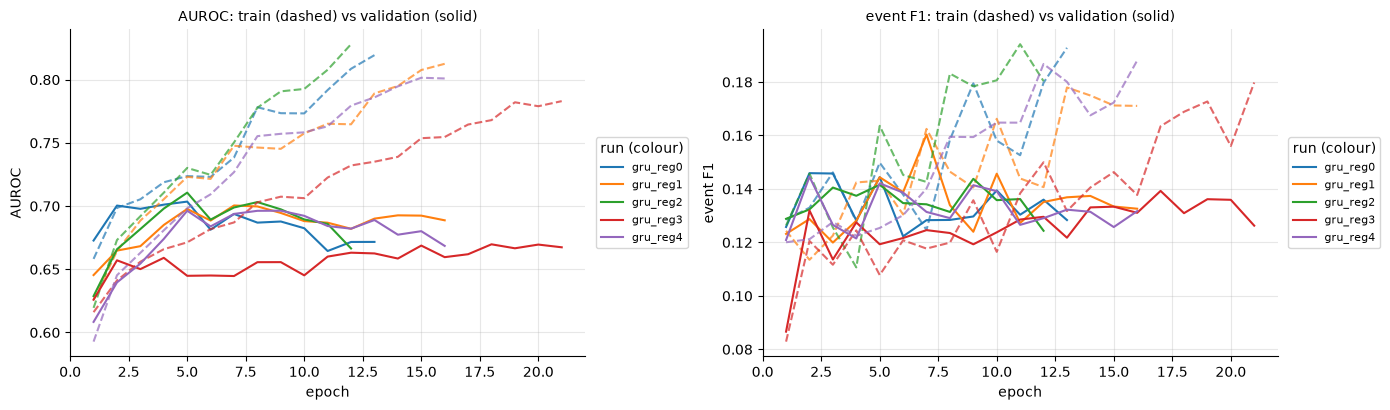

In [21]:
curves(grus, [("train_auroc", "val_auroc", "AUROC"), ("train_f1", "val_f1", "event F1")], figsize=(14, 4.2))

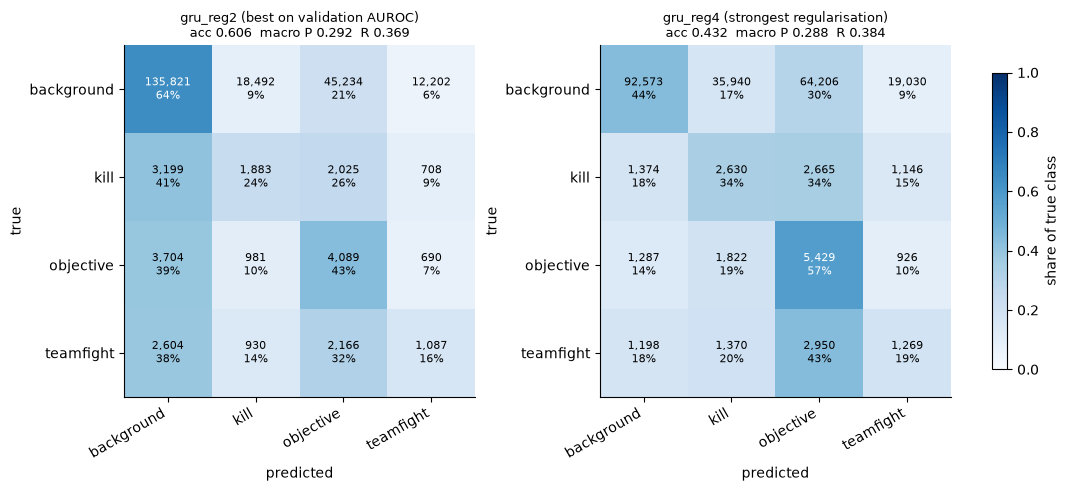

In [22]:
cm_grid(["gru_reg2", "gru_reg4"], "test", ncols=2, titles={"gru_reg2": "gru_reg2 (best on validation AUROC)", "gru_reg4": "gru_reg4 (strongest regularisation)"})

`gru_reg4` looks better in its confusion matrix (more events found) but is it? The next cell compares both models **at the same background recall**, with the scaling of the background probability chosen on validation (needs the cached data).

In [23]:
def step_probs(model, eval_set):
    P, Y = [], []
    with torch.no_grad():
        for _, x, y in eval_set.groups:
            out = model(x.float())
            logits = out["logits"] if isinstance(out, dict) else out
            P.append(torch.softmax(logits, 1).permute(0, 2, 1).reshape(-1, len(CLASSES)))
            Y.append(y.reshape(-1))
    return torch.cat(P), torch.cat(Y)


def recall_precision(P, Y, factor):
    q = P.clone()
    q[:, 0] *= factor
    cm = torch.bincount(Y * 4 + q.argmax(1), minlength=16).view(4, 4).float()
    return (cm.diag() / cm.sum(1)).cpu().numpy(), (cm.diag() / cm.sum(0).clamp(min=1)).cpu().numpy()


def load_model(name):
    ck = torch.load(ROOT / "checkpoints" / f"{name}.pt", map_location="cpu", weights_only=True)
    net = build_model(ck["arch"], ck["in_dim"], **ck["model_kwargs"])
    net.load_state_dict(ck["state_dict"])
    return net.to(device).eval(), ck


_sets = {}


def get_sets(offset, splits=("val", "test")):
    # EvalSets on the device for the given label offset (cached)
    for sp in splits:
        if (offset, sp) not in _sets:
            gs = GpuSplit(DATA_ROOT, sp, {**base_cfg, "label_offset_s": offset}, device)
            _sets[(offset, sp)] = EvalSet(gs, range(len(gs)))
    return {sp: _sets[(offset, sp)] for sp in splits}


if HAVE_DATA:
    probs = {}
    for name in ("gru_reg2", "gru_reg4"):
        net, _ = load_model(name)
        sets = get_sets(float(manifest.loc[name, "label_offset_s"]))
        probs[name] = {sp: step_probs(net, sets[sp]) for sp in ("val", "test")}
    rows = []
    for target in (0.80, 0.64, 0.44):
        for name in probs:
            Pv, Yv = probs[name]["val"]
            lo, hi = 0.01, 100.0
            for _ in range(40):
                mid = (lo * hi) ** 0.5
                lo, hi = (mid, hi) if recall_precision(Pv, Yv, mid)[0][0] < target else (lo, mid)
            rec, prec = recall_precision(*probs[name]["test"], (lo * hi) ** 0.5)
            rows.append({"target background recall": target, "model": name, "background recall": rec[0],
                         "kill R": rec[1], "kill P": prec[1], "objective R": rec[2], "objective P": prec[2],
                         "teamfight R": rec[3], "teamfight P": prec[3], "macro R": rec.mean(), "mean event P": prec[1:].mean()})
    display(pd.DataFrame(rows).set_index(["target background recall", "model"]).style.format("{:.3f}"))
else:
    print("cached data not found; run: python -m detection.gpu_data --splits val test")

**What we learned.**

* Harder regularisation did **not** lift test AUROC to 0.7: it stays at 0.69 for `gru_reg0` and `gru_reg2` (the best on validation, 0.711), and is lower for the more extreme settings. The smaller one-layer model (`gru_reg3`) is the worst.
* All of the runs overfit within 12 to 21 epochs (train AUROC reaches 0.73 to 0.76, validation stays at 0.67 to 0.71); the strongest regularisation raised *train* AUROC the most and *test* AUROC the least.
* `gru_reg4` is **not** better than `gru_reg2`. Its confusion matrix looks better only because its default threshold calls more steps events. At the same background recall the two models are indistinguishable (macro recall and precision within about 0.02 to 0.03), and `gru_reg2` has the higher AUROC on validation and test.
* `gru_reg2` is therefore the final model, selected on validation.

### 4.9 Scaling up: a 116M-parameter transformer

**Question.** Temporal modelling gave the biggest gains, and attention is the usual next step. The hypothesis to test: *a transformer's performance rises with its size, if it is trained long enough.* The captioning transformers of the dataset paper are out of reach on an 11 GB GPU, but the sequences here are short (median 71 steps, longest 1,216), so a transformer **encoder** over the projected features is affordable. The plan was to build the largest one that fits and train it for 100 epochs, with the +6 s labels (the best offset on validation) and background downsampling.

**Architecture.** `TransformerEventNet`: input dropout and a 1x1 projection from 4,096 features to `d_model`, sinusoidal position encodings, `layers` pre-norm self-attention blocks over the whole clip (padded steps are masked out of the attention keys), a final layer norm and a per-step linear classifier. Optional extras: input noise, **stochastic depth** (skip whole layers at random during training), and **gradient checkpointing**.

**How big can it be?** The cached training features occupy about 7.8 GB of the GPU's 10.9 GB, which leaves about 3 GB for the weights, the optimiser state (AdamW keeps about 16 bytes per parameter) and the activations. The activations are dominated by the longest clips, so I capped the training windows at 384 steps (only about 5% of clips are longer; evaluation always uses the full clip), batched clips of similar length together to reduce padding, and used gradient checkpointing for the biggest models. The table shows the measured peak memory.

In [24]:
mem = pd.DataFrame([
    ("64 / 2 / 4",     "0.33M",  "0.99", "0.33", "-"),
    ("128 / 4 / 4",    "1.06M",  "1.20", "0.40", "-"),
    ("192 / 6 / 6",    "3.46M",  "2.32", "0.77", "-"),
    ("256 / 6 / 8",    "5.79M",  "2.89", "0.97", "-"),
    ("384 / 8 / 8",    "15.8M",  "5.12", "1.78", "-"),
    ("512 / 8 / 8",    "27.3M",  "6.67", "2.41", "0.90"),
    ("512 / 12 / 8",   "39.9M",  "9.61", "3.47", "-"),
    ("768 / 12 / 12",  "88.2M",  "out of memory", "5.51", "1.94"),
    ("768 / 16 / 12",  "116.6M", "-", "-", "2.43  (chosen)"),
    ("1024 / 12 / 16", "155.4M", "-", "-", "out of memory"),
    ("1024 / 16 / 16", "205.7M", "-", "-", "out of memory"),
], columns=["width / layers / heads", "parameters",
            "peak GB, no checkpointing, batch 16 x 1,216 steps", "peak GB, no checkpointing, batch 16 x 380 steps",
            "peak GB, with checkpointing, batch 16 x 384, next to 7.8 GB of data"])
display(mem.style.hide(axis="index"))
print("measured on the project GPU (GTX 1080 Ti, 10.9 GiB) with random data; the feed-forward width is 4 x the model width")

width / layers / heads,parameters,"peak GB, no checkpointing, batch 16 x 1,216 steps","peak GB, no checkpointing, batch 16 x 380 steps","peak GB, with checkpointing, batch 16 x 384, next to 7.8 GB of data"
64 / 2 / 4,0.33M,0.99,0.33,-
128 / 4 / 4,1.06M,1.20,0.40,-
192 / 6 / 6,3.46M,2.32,0.77,-
256 / 6 / 8,5.79M,2.89,0.97,-
384 / 8 / 8,15.8M,5.12,1.78,-
512 / 8 / 8,27.3M,6.67,2.41,0.90
512 / 12 / 8,39.9M,9.61,3.47,-
768 / 12 / 12,88.2M,out of memory,5.51,1.94
768 / 16 / 12,116.6M,-,-,2.43 (chosen)
1024 / 12 / 16,155.4M,-,-,out of memory


measured on the project GPU (GTX 1080 Ti, 10.9 GiB) with random data; the feed-forward width is 4 x the model width


The largest size that fits is **16 layers, width 768, 12 heads, feed-forward 3,072: 116.6M parameters**, with a worst-case step peaking at 2.4 GB of the 3.1 GB available (the next size, 155M, runs out of memory). A guard in the trainer skips and logs any batch that does run out of memory; none did.

**Training setup.** Two runs of this model. The first (`tf_max`) used moderate regularisation and no early stopping. It overfitted, so the second (`tf_max_reg`) changed only the regularisation (and added a patient stopping rule). Everything else was the same.

In [25]:
cfg_a = yaml.safe_load((ROOT / "detection" / "configs" / "tf_max.yaml").read_text())
cfg_b = yaml.safe_load((ROOT / "detection" / "configs" / "tf_max_reg.yaml").read_text())
ma, mb = cfg_a["model"]["transformer"], cfg_b["model"]["transformer"]


def fmt(v):
    return f"{v:g}" if isinstance(v, float) else v


def best_epoch(run):
    h = pd.DataFrame(H[run]["history"])
    return int(h.loc[h["val_auroc"].idxmax(), "epoch"])


rows = [
    ("Architecture", f"{ma['layers']} layers, width {ma['d_model']}, {ma['heads']} heads, feed-forward {ma['ff']}", "same"),
    ("Parameters", f"{int(manifest.loc['tf_max', 'parameters']):,}", "same"),
    ("Labels", f"offset {cfg_a['label_offset_s']:+g} s (best on validation), 3 s window", "same"),
    ("Background handling", "downsampled per batch to the mean event-class count (bg_keep: balance), no class weights", "same"),
    ("Dropout (attention, feed-forward, residual)", ma["dropout"], mb["dropout"]),
    ("Input dropout (on the 4,096 features)", ma["in_dropout"], mb["in_dropout"]),
    ("Input noise (std, standardised units)", ma["noise_std"], mb["noise_std"]),
    ("Stochastic depth (max, rises with depth)", ma.get("drop_path", 0.0), mb.get("drop_path", 0.0)),
    ("Optimiser", "AdamW", "same"),
    ("Learning rate", cfg_a["lr"], cfg_b["lr"]),
    ("Warm-up / schedule", f"{cfg_a['lr_warmup_epochs']} epochs linear, then cosine to {cfg_a['lr_min_frac']:.0%}", "same"),
    ("Weight decay", cfg_a["weight_decay"], cfg_b["weight_decay"]),
    ("Label smoothing", cfg_a["label_smoothing"], cfg_b["label_smoothing"]),
    ("Gradient clipping", cfg_a["grad_clip"], "same"),
    ("Batch size / batching", f"{cfg_a['batch_size']} clips, similar lengths batched together", "same"),
    ("Training window cap", f"{cfg_a['max_train_len']} steps (longer clips cropped at random each epoch)", "same"),
    ("Memory", "gradient checkpointing; about 10.4 GB of 10.9 GB used", "same"),
    ("Checkpoint selection", "best validation AUROC (monitor: 500 fixed training clips vs all validation clips)", "same"),
    ("Early stopping", "none (divergence rule off)", "none for 30 epochs without a new best (stall rule)"),
    ("Epochs planned / run", f"{cfg_a['epochs']} / {H['tf_max']['epochs_run']} (stopped by hand)", f"{cfg_b['epochs']} / {H['tf_max_reg']['epochs_run']} (stopped by hand)"),
    ("Best validation epoch (checkpoint kept)", best_epoch("tf_max"), best_epoch("tf_max_reg")),
    ("Time per epoch", "about 3.7 minutes", "about 3.7 minutes"),
]
setup = pd.DataFrame([(a, fmt(b), fmt(c)) for a, b, c in rows], columns=["setting", "tf_max (run 1)", "tf_max_reg (run 2)"]).set_index("setting")
display(setup.style.set_properties(**{"text-align": "left"}))

,tf_max (run 1),tf_max_reg (run 2)
setting,,
Architecture,"16 layers, width 768, 12 heads, feed-forward 3072",same
Parameters,"116,557,060",same
Labels,"offset +6 s (best on validation), 3 s window",same
Background handling,"downsampled per batch to the mean event-class count (bg_keep: balance), no class weights",same
"Dropout (attention, feed-forward, residual)",0.3,0.5
"Input dropout (on the 4,096 features)",0.5,0.7
"Input noise (std, standardised units)",0.3,0.5
"Stochastic depth (max, rises with depth)",0,0.3
Optimiser,AdamW,same


The two smaller transformers (`tf_s`, 2 layers of width 64, and `tf_l`, 6 layers of width 256) are earlier short runs of the same code with the divergence rule on (they stopped at epochs 20 and 15) and learning rates of 5e-4 and 2e-4. They complete a size ladder of 0.33M, 5.8M and 116.6M parameters.

**Results** (each model at its best validation epoch; `gru_reg2` is the BiGRU for reference):

In [26]:
show(table(["tf_s", "tf_l", "tf_max", "tf_max_reg", "gru_reg2"], ("train", "val", "test")))

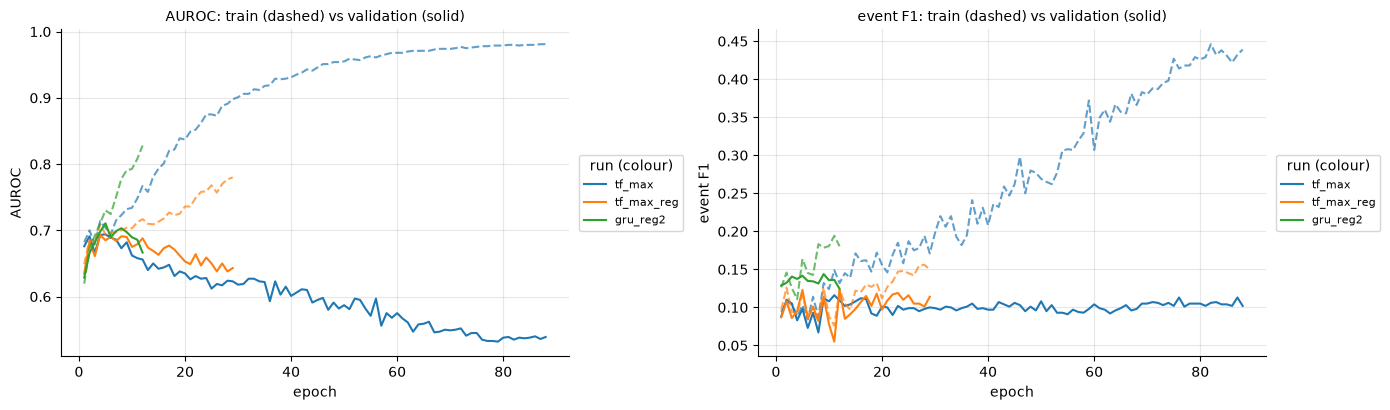

In [27]:
curves(["tf_max", "tf_max_reg", "gru_reg2"], [("train_auroc", "val_auroc", "AUROC"), ("train_f1", "val_f1", "event F1")], figsize=(14, 4.2))

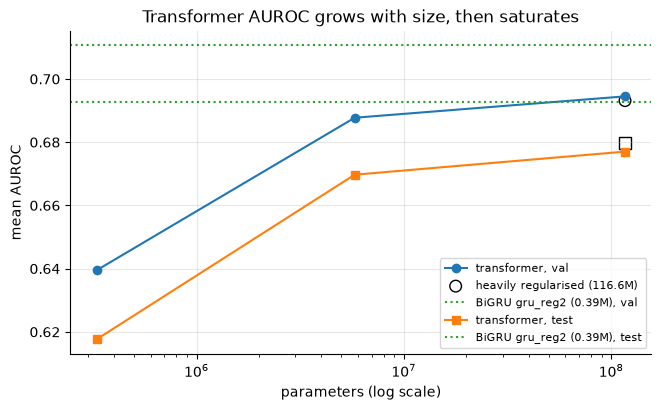

In [28]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ladder = ["tf_s", "tf_l", "tf_max"]
x = [int(manifest.loc[n, "parameters"]) for n in ladder]
for split, marker in (("val", "o"), ("test", "s")):
    ax.plot(x, [S[n][split]["rank"]["mean_auroc"] for n in ladder], marker + "-", label=f"transformer, {split}")
    ax.scatter([int(manifest.loc["tf_max_reg", "parameters"])], [S["tf_max_reg"][split]["rank"]["mean_auroc"]], marker=marker,
               facecolors="none", edgecolors="k", s=70, label="heavily regularised (116.6M)" if split == "val" else None)
    ax.axhline(S["gru_reg2"][split]["rank"]["mean_auroc"], ls=":", color="tab:green", label=f"BiGRU gru_reg2 (0.39M), {split}")
ax.set_xscale("log")
ax.set_xlabel("parameters (log scale)")
ax.set_ylabel("mean AUROC")
ax.set_title("Transformer AUROC grows with size, then saturates")
ax.legend(fontsize=8)
plt.show()

In [29]:
tfn = ["tf_s", "tf_l", "tf_max", "tf_max_reg", "gru_reg2"]
pcauc = pd.DataFrame({n: S[n]["test"]["rank"]["auroc"] for n in tfn}).T
pcauc.columns = [f"AUROC {c}" for c in pcauc.columns]
pcauc["teamfight recall at arg-max"] = [S[n]["test"]["step"]["per_class"]["teamfight"]["recall"] for n in pcauc.index]
display(Markdown("**Per-class test AUROC** (threshold-free), and how often the arg-max picks `teamfight`"))
display(pcauc.style.format("{:.3f}"))

**Per-class test AUROC** (threshold-free), and how often the arg-max picks `teamfight`

,AUROC kill,AUROC objective,AUROC teamfight,teamfight recall at arg-max
tf_s,0.571,0.648,0.634,0.090
tf_l,0.636,0.697,0.676,0.147
tf_max,0.634,0.703,0.694,0.085
tf_max_reg,0.646,0.710,0.683,0.026
gru_reg2,0.681,0.710,0.687,0.160


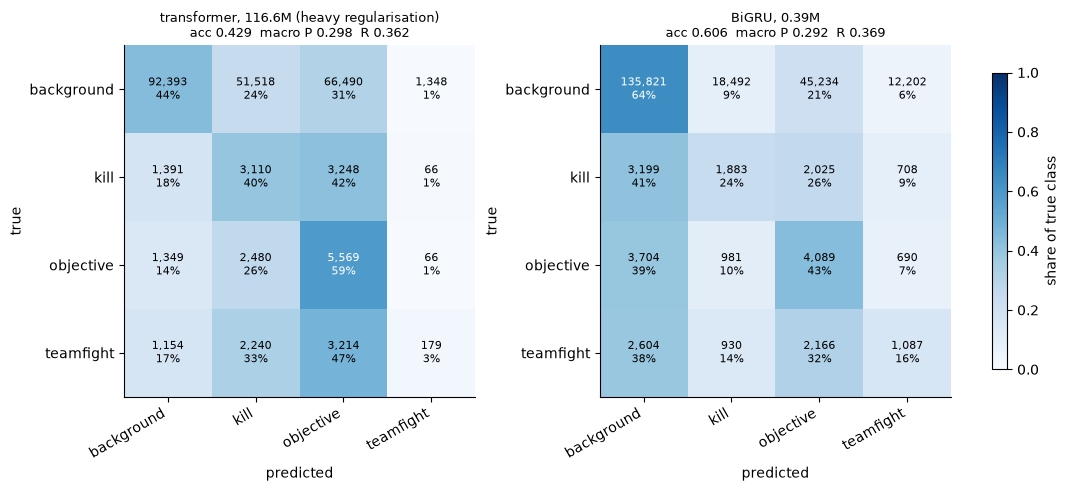

In [30]:
cm_grid(["tf_max_reg", "gru_reg2"], "test", ncols=2, titles={"tf_max_reg": "transformer, 116.6M (heavy regularisation)", "gru_reg2": "BiGRU, 0.39M"})

**What we learned.**

* **Size helps, then saturates.** Test AUROC goes 0.618 (0.33M) to 0.670 (5.8M) to 0.677 (116.6M; 0.680 with heavy regularisation). The jump from small to medium is large (+0.05), the 20-fold step from medium to huge adds under 0.01. So the hypothesis is partly right: scale helps up to a point. Caution: the two small runs are short runs with other learning rates, so this is indicative, not a controlled scaling study.
* **Training longer did not help; it hurt.** The first 116.6M run reached its best validation AUROC (0.694) at **epoch 5**. For the next 83 epochs validation AUROC fell steadily, to 0.54 at epoch 88, while train AUROC climbed to 0.98: the model memorised the noisy training labels. The plan to train 100 epochs was abandoned at epoch 88. Slow learning was not the issue; the model learned what generalises almost immediately.
* **Heavier regularisation slowed the overfitting but did not change the peak.** With dropout 0.5, input dropout 0.7, input noise 0.5, stochastic depth 0.3, a learning rate of 2e-5, weight decay 0.3 and label smoothing 0.1, at epoch 29 train AUROC was 0.78 and validation 0.64 (a gap of 0.14), against 0.90 and 0.62 (a gap of 0.28) for the first run at the same epoch, and the first run's gap kept widening to 0.44. Both runs peak at the same validation AUROC (0.693 to 0.694) within the first 5 epochs, so a regulariser could not raise the ceiling.
* **The best transformer is below the BiGRU.** Test AUROC 0.680 against 0.693, from a model about 300 times larger. The transformers also have a lower event F1 (about 0.09 to 0.11 against 0.138): the saved checkpoints come from the first epochs, when the class probabilities are still poorly calibrated for the event-extraction threshold.
* **The deficit is on `kill`.** Per class, the two 116.6M transformers match the BiGRU on `objective` (AUROC 0.70 to 0.71) and `teamfight` (0.68 to 0.69) but trail on `kill` (0.634 to 0.646 against 0.681). The confusion matrix shows the 116.6M transformers rarely predicting `teamfight` (recall 0.03 to 0.09 against 0.16), even though its `teamfight` AUROC is as good: that is the operating point (the `teamfight` probability rarely wins the arg-max in these early checkpoints), not a ranking failure. The matrix also lumps most background errors into `objective` and `kill`.
* **Interpretation.** With about 7,000 noisy clips, model capacity is not what limits performance; a larger model just memorises label noise faster. This is consistent with the earlier capacity result (a 6.4M-parameter U-Net no better than a 0.3M one). To do better, we need information the model does not have yet (cleaner labels, better features) or ways to average out the noise (ensembles).
* **Practical note.** The 116.6M checkpoints are 466 MB each and are kept out of git.

## 5. Overall comparison

All 35 checkpoints on the **test** set. Rows are grouped by label offset (compare within a group). Each model uses the `min_conf` chosen on validation.

In [31]:
order = manifest.sort_values(["label_offset_s"], kind="stable").index
allt = table(list(order), ("test",))
allt.insert(0, "label offset (s)", manifest.loc[order, "label_offset_s"].values)
allt.insert(1, "params", manifest.loc[order, "parameters"].astype(int).values)
allt = allt.sort_values(["label offset (s)", "AUROC"], ascending=[True, False])
allt[["label offset (s)", "params", "acc", "AUROC", "step R", "step F1", "event F1", "loss"]].to_csv(OUT / "test_comparison_all.csv")
display(show(allt[["label offset (s)", "params", "acc", "AUROC", "AP lift", "step R", "step F1", "event P", "event R", "event F1", "loss"]], hi=()).format({"params": "{:,}", "label offset (s)": "{:+.0f}"}))

,label offset (s),params,acc,AUROC,AP lift,step R,step F1,event P,event R,event F1,loss
model,,,,,,,,,,,
shift_m9,-9,"121,428",0.768747,0.603515,1.475579,0.299233,0.276141,0.076500,0.173825,0.102412,1.083966
shift_m6,-6,"121,428",0.748561,0.615261,1.604196,0.312599,0.282872,0.081507,0.195304,0.113384,1.099714
shift_m3,-3,"121,428",0.761703,0.611339,1.532126,0.295517,0.280058,0.089853,0.189488,0.120980,1.087209
shift0,+0,"121,428",0.738019,0.616970,1.558398,0.304665,0.288609,0.114300,0.258019,0.155990,1.050530
reg4_c,+0,"121,428",0.819918,0.613368,1.575521,0.279359,0.280733,0.137219,0.133193,0.128832,0.757907
wt075,+0,"121,428",0.695401,0.608689,1.579603,0.311768,0.284090,0.110793,0.277551,0.158337,1.003999
reg2_c,+0,"1,149,252",0.812132,0.605623,1.569371,0.283542,0.284768,0.124442,0.161192,0.135545,0.776424
reg5_c,+0,"1,149,252",0.837351,0.603498,1.559410,0.275204,0.278500,0.134928,0.109758,0.115391,0.787655
wt100_h32,+0,"353,444",0.067973,0.602713,1.529073,0.305055,0.078639,0.083788,0.424050,0.134920,1.732200


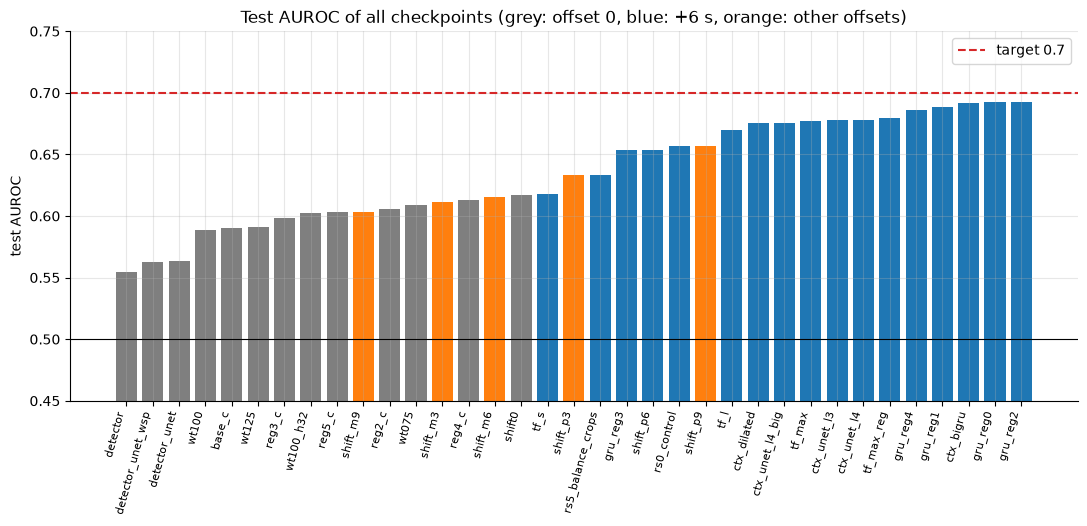

In [32]:
fig, ax = plt.subplots(figsize=(13, 4.8))
d = allt.sort_values("AUROC")
colors = {0.0: "tab:grey", 6.0: "tab:blue"}
ax.bar(range(len(d)), d["AUROC"], color=[colors.get(o, "tab:orange") for o in d["label offset (s)"]])
ax.axhline(0.5, color="k", lw=0.8)
ax.axhline(0.7, color="tab:red", ls="--", label="target 0.7")
ax.set_ylim(0.45, 0.75)
ax.set_xticks(range(len(d)))
ax.set_xticklabels(d.index, rotation=75, ha="right", fontsize=8)
ax.set_ylabel("test AUROC")
ax.set_title("Test AUROC of all checkpoints (grey: offset 0, blue: +6 s, orange: other offsets)")
ax.legend()
plt.show()

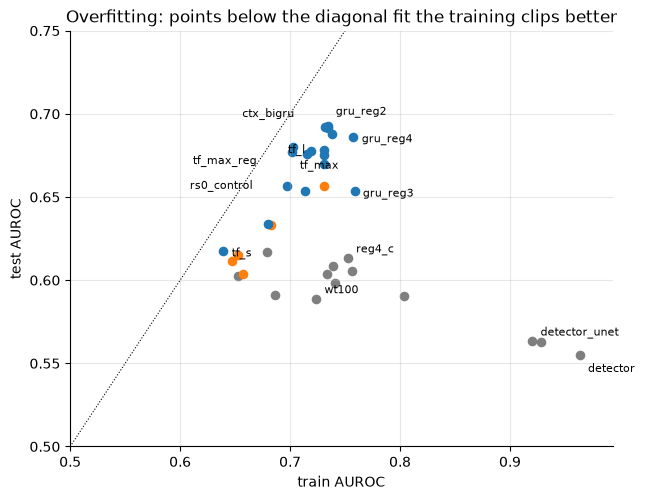

In [33]:
fig, ax = plt.subplots(figsize=(7, 5.4))
labelled = {"detector_unet": (6, 4), "detector": (6, -12), "reg4_c": (6, 4), "rs0_control": (-70, -2), "ctx_bigru": (-62, 8),
            "gru_reg2": (6, 8), "gru_reg4": (6, -4), "gru_reg3": (6, -4), "wt100": (6, 4), "tf_max": (6, -12), "tf_max_reg": (-72, -12),
            "tf_l": (-26, 8), "tf_s": (6, -4)}
for n in manifest.index:
    tr, te = S[n]["train"]["rank"]["mean_auroc"], S[n]["test"]["rank"]["mean_auroc"]
    ax.scatter(tr, te, color=colors.get(float(manifest.loc[n, "label_offset_s"]), "tab:orange"), s=35)
    if n in labelled:
        ax.annotate(n, (tr, te), fontsize=8, xytext=labelled[n], textcoords="offset points")
top = max(S[n]["train"]["rank"]["mean_auroc"] for n in manifest.index) + 0.03
lim = [0.5, top]
ax.plot(lim, lim, "k:", lw=0.8)
ax.set_xlim(lim)
ax.set_ylim(0.5, 0.75)
ax.set_xlabel("train AUROC")
ax.set_ylabel("test AUROC")
ax.set_title("Overfitting: points below the diagonal fit the training clips better")
plt.show()

**Reading the overall picture.**

* Within each label offset, the progression is visible: the first U-Nets (test AUROC about 0.56), regularised U-Nets (about 0.60 to 0.61), the +6 s labels (about 0.65 to 0.66), a wider context (up to 0.69).
* **Accuracy and F1 mostly reflect the operating point** (how many steps are called events), so they vary a lot between models that separate classes equally well. AUROC is the cleanest comparison.
* Every point lies below the diagonal in the second plot: all models fit the training clips better than the test clips, and the best test models are not the best-fitting ones.

## 6. The best model in detail: `gru_reg2`

A 2-layer bidirectional GRU (hidden 64, 387k parameters) on +6 s labels, trained with background downsampling, dropout 0.4, input dropout 0.6, input noise 0.5, weight decay 0.1, learning rate 5e-4 and label smoothing 0.1; the run was stopped by the divergence monitor at epoch 12, and the saved checkpoint is the epoch with the best validation AUROC.

In [34]:
best = "gru_reg2"
display(show(table([best], ("train", "val", "test")), hi=()))
pc = pd.DataFrame(S[best]["test"]["step"]["per_class"]).T.rename(columns=str.title)
pc["Support (steps)"] = pc.pop("Support").astype(int)
pc["AUROC"] = pd.Series(S[best]["test"]["rank"]["auroc"])
pc["AP"] = pd.Series(S[best]["test"]["rank"]["ap"])
pc["Base rate"] = pd.Series(S[best]["test"]["rank"]["base_rate"])
display(Markdown("**Per-class test metrics** (step level, with one-vs-rest AUROC and AP)"))
display(pc.style.format({c: "{:.3f}" for c in pc.columns if c != "Support (steps)"}))

**Per-class test metrics** (step level, with one-vs-rest AUROC and AP)

,Precision,Recall,F1,Support (steps),AUROC,AP,Base rate
background,0.935,0.641,0.761,211749,nan,nan,nan
kill,0.084,0.241,0.125,7815,0.681,0.066,0.033
objective,0.076,0.432,0.130,9464,0.710,0.079,0.040
teamfight,0.074,0.160,0.101,6787,0.687,0.054,0.029


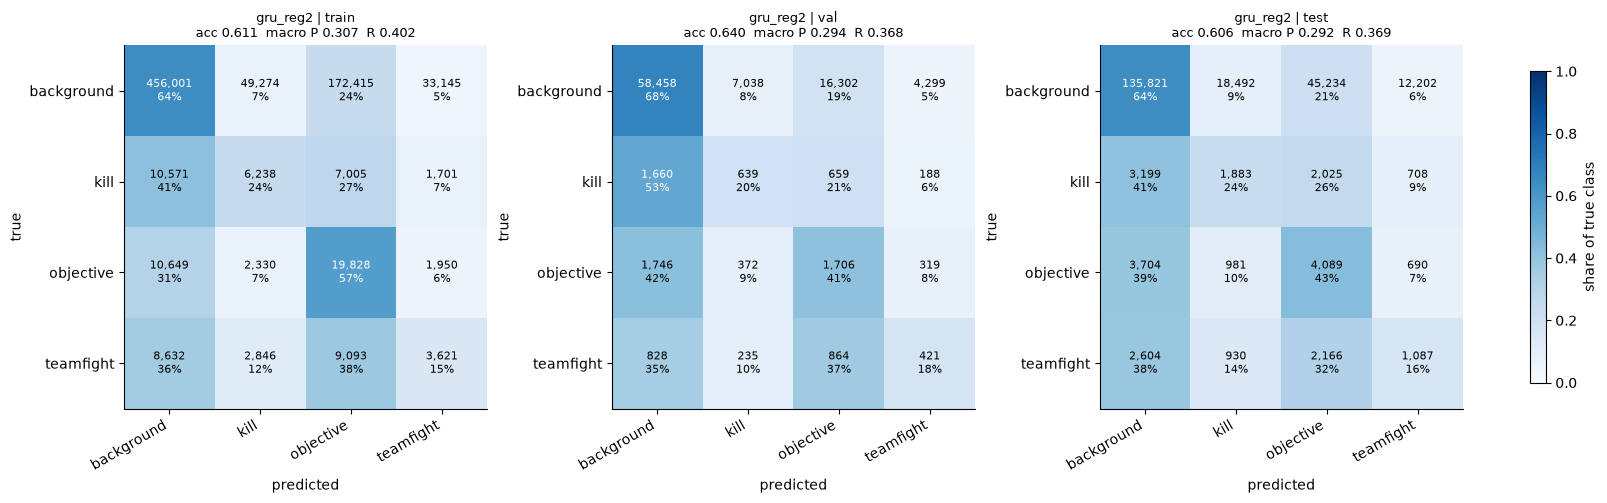

**Test confusion matrix, raw step counts**

,pred background,pred kill,pred objective,pred teamfight
true background,135821,18492,45234,12202
true kill,3199,1883,2025,708
true objective,3704,981,4089,690
true teamfight,2604,930,2166,1087


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.9), layout="constrained")
for ax, sp in zip(axes, ("train", "val", "test"), strict=True):
    im = draw(ax, S[best][sp]["step"], f"{best} | {sp}")
    ax.grid(False)
fig.colorbar(im, ax=axes.tolist(), shrink=0.8, label="share of true class")
fig.savefig(OUT / "best_model_confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()
cm = pd.DataFrame(S[best]["test"]["step"]["confusion_matrix"], index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES])
display(Markdown("**Test confusion matrix, raw step counts**"))
display(cm)

**Reading the confusion matrix.** Because background is downsampled in training, the model no longer predicts everything as background: 64% of background steps are right, and 24% of `kill`, 43% of `objective` and 16% of `teamfight` steps are found. The price is **precision**: of the steps the model calls an event, only about 7 to 8% are right, because the many background steps that are called events outnumber the true event steps. The train and test matrices have the same shape; the training one is only slightly better, which fits an AUROC of 0.73 on train and 0.69 on test.

### Precision/recall trade-off

Class weights and background downsampling only choose a point on one trade-off curve. Multiplying the background probability by a factor before taking the arg-max traces that curve for `gru_reg2` on the test set: a factor above 1 predicts more background, below 1 finds more events. Pick the point you need.

,background recall,kill recall,objective recall,teamfight recall,mean event recall,mean event precision
background factor,,,,,,
0.250000,0.214,0.462,0.650,0.173,0.428,0.059
0.500000,0.315,0.425,0.632,0.172,0.410,0.063
0.750000,0.482,0.331,0.562,0.168,0.354,0.070
1.000000,0.641,0.241,0.432,0.160,0.278,0.078
1.500000,0.859,0.091,0.203,0.111,0.135,0.095
2.000000,0.956,0.019,0.074,0.052,0.049,0.117
3.000000,0.998,0.000,0.002,0.001,0.001,0.050
5.000000,1.000,0.000,0.000,0.000,0.000,0.000


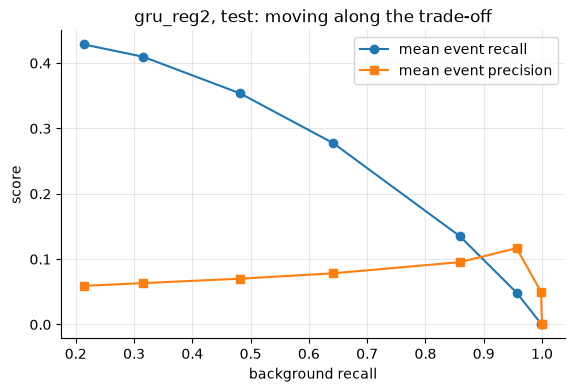

In [36]:
if HAVE_DATA:
    P, Y = probs["gru_reg2"]["test"]
    rows = []
    for f in [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 5]:
        rec, prec = recall_precision(P, Y, f)
        rows.append({"background factor": f, "background recall": rec[0], "kill recall": rec[1], "objective recall": rec[2],
                     "teamfight recall": rec[3], "mean event recall": rec[1:].mean(), "mean event precision": prec[1:].mean()})
    tradeoff = pd.DataFrame(rows).set_index("background factor")
    display(tradeoff.style.format("{:.3f}"))
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(tradeoff["background recall"], tradeoff["mean event recall"], "o-", label="mean event recall")
    ax.plot(tradeoff["background recall"], tradeoff["mean event precision"], "s-", label="mean event precision")
    ax.set_xlabel("background recall")
    ax.set_ylabel("score")
    ax.set_title("gru_reg2, test: moving along the trade-off")
    ax.legend()
    plt.show()
else:
    print("cached data not found; run: python -m detection.gpu_data --splits val test")

### An example clip

Predicted event probabilities against the labelled windows for one validation clip (of the typical-length clips, 22 to 30 s, the one with the most event steps). The model has to find 3-second windows in noisy, loosely aligned labels, and it does so only partly, which is what the metrics above summarise.

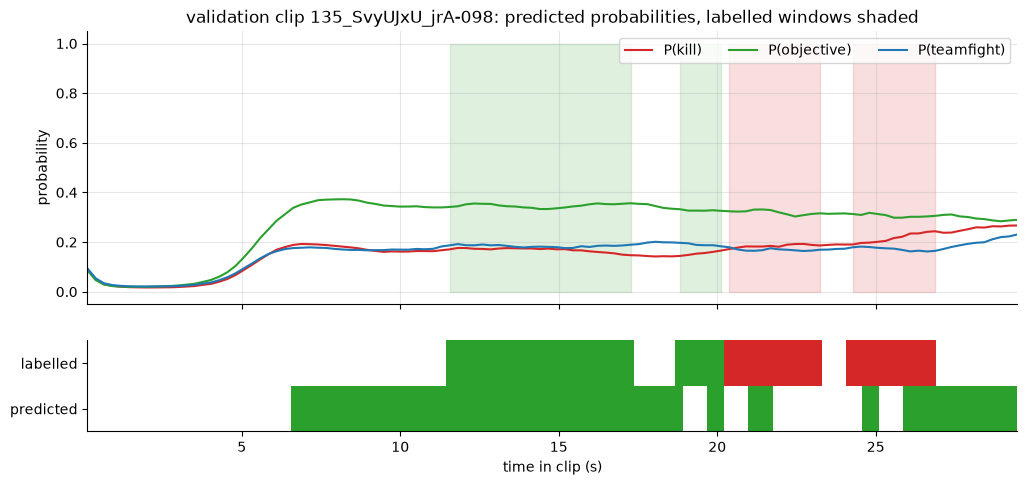

In [37]:
if HAVE_DATA:
    gs = GpuSplit(DATA_ROOT, "val", {**base_cfg, "label_offset_s": 6.0}, device)
    cands = [(int((y > 0).sum()), len(y), i) for i, y in enumerate(gs.y) if 100 <= len(y) <= 140]
    i = max(cands)[2]
    net, _ = load_model("gru_reg2")
    with torch.no_grad():
        p = torch.softmax(net(gs.clip(i).T[None].float()), 1)[0].cpu().numpy()
    t, y = gs.times[i], gs.y[i].cpu().numpy()
    col = {1: "tab:red", 2: "tab:green", 3: "tab:blue"}
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    for k in (1, 2, 3):
        a1.plot(t, p[k], color=col[k], label=f"P({CLASSES[k]})")
        a1.fill_between(t, 0, 1, where=(y == k), color=col[k], alpha=0.15)
    a1.set_ylabel("probability")
    a1.set_title(f"validation clip {gs.ids[i]}: predicted probabilities, labelled windows shaded")
    a1.legend(loc="upper right", ncol=3)
    a2.imshow(np.stack([y, p.argmax(0)]), aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["white", "tab:red", "tab:green", "tab:blue"]),
              extent=[t[0], t[-1], 0, 2], vmin=0, vmax=3)
    a2.set_yticks([0.5, 1.5])
    a2.set_yticklabels(["predicted", "labelled"])
    a2.set_xlabel("time in clip (s)")
    a2.grid(False)
    plt.show()
else:
    print("cached data not found; run: python -m detection.gpu_data --splits val test")

## 7. Conclusions, limitations and next steps

### What worked
* **Regularising the U-Net** (a much smaller first layer, input dropout, input noise, weight decay): test AUROC 0.56 to 0.61, the largest single gain.
* **Shifting the label window later** (about +6 s): about +0.04 AUROC on test.
* **A wider temporal context**, especially a **BiGRU over the whole clip**: another +0.03 on test, with a small model.
* **Early stopping on a train-versus-validation monitor** that uses identical metrics for both, and **choosing the threshold on validation**: these prevented several wrong conclusions.
* **Background downsampling** gives a usable confusion matrix (events are found) at an operating point you can choose.

### What did not
* Class weights, downsampling and crops: they move the operating point; AUROC stays the same or drops.
* More capacity: a 6.4M-parameter U-Net, and a 116.6M-parameter transformer (test AUROC 0.680, below the 0.39M-parameter BiGRU at 0.693). Also the variational parts, gradient-free weight editing, and heavier regularisation of the BiGRU.

### Limitations
* **The labels are noisy**: keyword matches in commentary, with unknown and variable lag. That caps every score, including on the training clips (train AUROC is only 0.73).
* **The target is not reached:** the best test AUROC is 0.693 (validation 0.711), just under 0.7.
* One seed per configuration. Differences of about 0.01 in AUROC or F1 are within noise; the larger effects (offset, context) are consistent between validation and test.
* The 500-clip train monitor and the 3-second window are design choices; other windows would change the scores.
* The transformer results use checkpoints from the first 4 to 5 epochs of runs I stopped by hand; the two small transformers were short runs under a different stopping rule and learning rates, so the size comparison is indicative, not a controlled scaling study. Only sinusoidal absolute positions were tried.
* Models with different label offsets are scored against different labels; only compare within an offset.

### Next steps
1. **Average several models** (BiGRU seeds plus the wider U-Nets): cheap, and usually worth +0.01 to +0.02 AUROC, which would put test past 0.7.
2. **Soft or wider label windows** to absorb the caption timing noise (this changes the task, so scores are not comparable with the table above).
3. **A small hand-labelled subset** to measure how much of the ceiling is label noise.
4. **Per-class label offsets**, since `objective` and `teamfight` gained more from the later window than `kill`.
5. **Lighter attention variants** instead of a bigger transformer: one self-attention layer on top of the BiGRU, local (windowed) attention, relative position biases, and a gated fusion of the RGB and flow halves of the features.

---
## Appendix A: evaluate any checkpoint yourself

The cells below repeat, for one checkpoint, what was done to produce the tables above. Change `name` to any checkpoint listed in `checkpoints/README.md`.

**Step 1: load the checkpoint.** A checkpoint holds only tensors plus `arch`, `model_kwargs`, `in_dim` and the aggregator settings, so it loads with `weights_only=True` and the network is rebuilt with `build_model`.

In [38]:
name = "gru_reg2"  # any name from checkpoints/manifest.json
net, ck = load_model(name)
print("architecture :", ck["arch"], ck["model_kwargs"])
print("parameters   :", f"{sum(p.numel() for p in net.parameters()):,}")
print("label offset :", manifest.loc[name, "label_offset_s"], "s")

architecture : bigru {'hidden': 64, 'layers': 2, 'dropout': 0.4, 'in_dropout': 0.6, 'noise_std': 0.5}
parameters   : 387,140
label offset : 6.0 s


**Step 2: load the validation and test data** for this model's label offset (needs the cached features; build them once with `python -m detection.gpu_data --splits val test`), and **Step 3: choose `min_conf` on validation.**

In [39]:
CONF_GRID = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]


def tune_conf(net, val_set, aggregator):
    scores = {c: evaluate(net, val_set, {**aggregator, "min_conf": c}, TOL)["mean_event_f1"] for c in CONF_GRID}
    return max(scores, key=scores.get), scores


if HAVE_DATA:
    sets = get_sets(float(manifest.loc[name, "label_offset_s"]))
    conf, scores = tune_conf(net, sets["val"], ck["aggregator"])
    display(pd.Series(scores, name="val event F1").rename_axis("min_conf").to_frame().T.round(3))
    print("chosen min_conf:", conf)

min_conf,0.2,0.3,0.4,0.5,0.6,0.7
val event F1,0.142,0.138,0.082,0.005,0.0,0.0


chosen min_conf: 0.2


**Step 4: evaluate on the test set** (loss, accuracy, step and event metrics, AUROC and AP) and **Step 5: look at the confusion matrix.**

,loss,acc,AUROC,AP lift,step R,step F1,event P,event R,event F1
gru_reg2,0.962,0.606,0.693,1.944,0.369,0.279,0.126,0.164,0.138


    true \ pred   backgroun       kill  objective  teamfight
    background       135821      18492      45234      12202
    kill               3199       1883       2025        708
    objective          3704        981       4089        690
    teamfight          2604        930       2166       1087


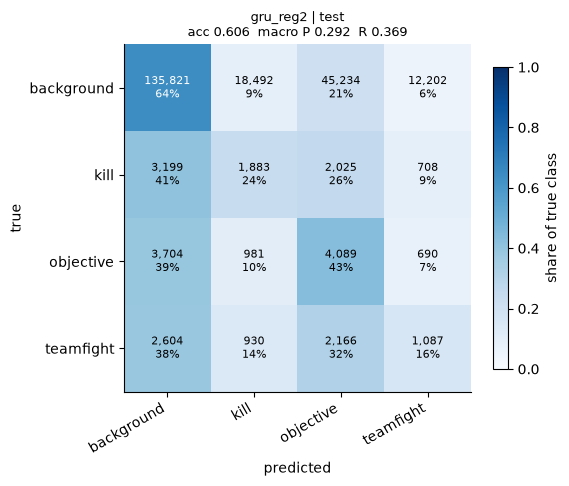

In [40]:
if HAVE_DATA:
    test = evaluate(net, sets["test"], {**ck["aggregator"], "min_conf": conf}, TOL)
    test["rank"] = rank_metrics(net, sets["test"])
    display(pd.Series(metrics_row(test), name=name).to_frame().T.style.format("{:.3f}"))
    print(show_matrix(test["step"]))
    fig, ax = plt.subplots(figsize=(5.6, 4.9))
    im = draw(ax, test["step"], f"{name} | test")
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label="share of true class")
    plt.show()

The numbers match the row for this checkpoint in the tables above (they come from the same function, `detection.score_all`, which does exactly these steps for every checkpoint and every split).

## Appendix B: how to reproduce

| What | Command |
|---|---|
| Environment | `make install-gpu` (CUDA) or `make install` |
| Download data | `make data` (about 16 GB) |
| Cache features (fp16, GPU-resident training) | `python -m detection.gpu_data --splits train val test` |
| Train a model | `python -m detection.train_gpu --config detection/configs/<config>.yaml --run-name <name>` |
| Score every checkpoint | `python -m detection.score_all --out visualisation/results/scores.json` |
| Confusion-matrix heatmaps | `python -m detection.plot_confusion --scores <scores.json>` |
| This report | open `visualisation/experiment_report.ipynb` and run all cells |

**Configs by experiment** (in `detection/configs/`): 4.3 `unet_base`, `unet_reg2` to `unet_reg5`; 4.4 `unet_wt075`, `unet_wt100`, `unet_wt125`, `unet_wt100_h32`; 4.5 `unet_shift_m9` to `unet_shift_p9`; 4.6 `unet_rs0_control`, `unet_rs5_balance_crops`; 4.7 `ctx_*`; 4.8 `gru_reg0` to `gru_reg4`; 4.9 `tf_s`, `tf_l`, `tf_max`, `tf_max_reg` (`tf100_*`, `tf_m`, `tf_xl` and `tf_xxl` are configs of runs that were cancelled). The first two baselines (4.1) and the weight-editing experiment (4.2) were run with `detection/train.py` and `detection/weight_search.py`.

**Large checkpoints.** `checkpoints/tf_max.pt` and `checkpoints/tf_max_reg.pt` (466 MB each) are not in git; the report needs only their scores, which are in `visualisation/results/scores.json`.

**Data files used by this report:** `checkpoints/` (weights and manifest), `visualisation/results/scores.json` (all scores and confusion matrices, produced by `detection.score_all`), `histories.json` (per-epoch training monitors), `early_curves.json` (logs of the first two runs), `weight_edit.json` (the weight-editing results).